# Ebene 1: Bedienqualität im KVV

Autor: Rustam T.

Wie gut ist eine Haltestelle oder eine Gemeinde im KVV angebunden, gemessen am veröffentlichten Soll-Fahrplan? Das Notebook nutzt einen einzigen gesammelten Stand und drei Stichtage (E9, Begründung in `docs/befunde.md`). Die Rechenlogik steckt in `analyse/` und ist getestet. Hier stehen nur Aufrufe, Tabellen und Grafiken.

**Datenquellen**
- Fahrplan: KVV GTFS über MobiData BW, CC0.
- Gemeindegrenzen und Einwohner: © BKG (2026) dl-de/by-2-0, Datenquellen: https://sgx.geodatenzentrum.de/web_public/gdz/datenquellen/datenquellen_vg_nuts.pdf. VG250-EW, Stand 31.12.2025, Einwohnerzahlen von Destatis. Für die Auswertung zugeschnitten auf die Gemeinden des KVV-Kerngebiets.

In [1]:
import os
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

REPO = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(REPO / "analyse"))

from gtfs import lies_stand
from bedienqualitaet import abfahrten_am_tag, tagestyp, takt_je_stunde
from gemeinden import (KERNGEBIET, abfahrten_im_abendfenster, je_gemeinde, lies_gemeinden,
                       ordne_zu, stationen_mit_koordinaten)

# Neuester Stand aus data/raw (den legt `python sammler/lade_landing_zone.py` dort ab)
STAND = sorted((REPO / "data" / "raw").glob("kvv_gtfs_*.zip"))[-1]
# Die VG250-EW liegt außerhalb des Repos, weil sie 115 MB groß ist
GEODATEN = Path(os.environ.get("KVV_GEODATEN", REPO.parent / "geodaten" / "vg250-ew_12-31.utm32s.gpkg.ebenen"
                               / "vg250-ew_ebenen_1231" / "DE_VG250.gpkg"))
GRAFIKEN = REPO / "docs" / "grafiken"
GRAFIKEN.mkdir(parents=True, exist_ok=True)

STICHTAGE = ["2026-11-10", "2026-11-14", "2026-11-15"]

# Farben: drei Tagestypen in fester Reihenfolge, Text in Grautönen
FARBE = {"Werktag": "#2a78d6", "Samstag": "#eb6834", "Sonntag": "#1baf7a"}
TEXT, TEXT2, RASTER = "#0b0b0b", "#52514e", "#e1e0d9"
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 200, "font.size": 10,
    "axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": "#c3c2b7",
    "axes.labelcolor": TEXT2, "xtick.color": TEXT2, "ytick.color": TEXT2,
    "axes.grid": True, "grid.color": RASTER, "grid.linewidth": 0.6, "axes.axisbelow": True,
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb",
})
print(STAND.name)

kvv_gtfs_2026-11-04T120817Z.zip


In [2]:
stand = lies_stand(STAND)
ab = {tag: abfahrten_am_tag(stand, tag) for tag in STICHTAGE}
takt = {tag: takt_je_stunde(ab[tag]) for tag in STICHTAGE}

pd.DataFrame({
    "Tagestyp": [tagestyp(t) for t in STICHTAGE],
    "Abfahrten": [len(ab[t]) for t in STICHTAGE],
    "Stationen mit Abfahrt": [ab[t]["station_id"].nunique() for t in STICHTAGE],
    "davon Rufbus-Abfahrten": [int((ab[t]["pickup_type"] == 2).sum()) for t in STICHTAGE],
}, index=pd.to_datetime(STICHTAGE).strftime("%a %d.%m.%Y"))

,Tagestyp,Abfahrten,Stationen mit Abfahrt,davon Rufbus-Abfahrten
Tue 10.11.2026,Werktag,163037,1961,5266
Sat 14.11.2026,Samstag,108335,1577,7556
Sun 15.11.2026,Sonntag,80204,1357,6933


## Wartezeit über den Tag

Erwartete Wartezeit nach E10: Wie lange wartet jemand, der zu einer zufälligen Minute an die Station kommt? Gezeigt ist der Median über alle Stationen, die in der Stunde mindestens eine Abfahrt haben.

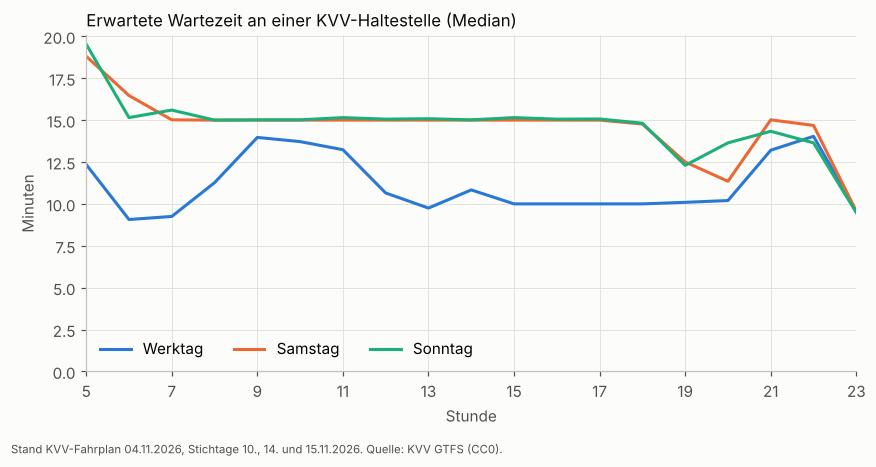

In [3]:
fig, ax = plt.subplots(figsize=(8, 4.2))
for tag in STICHTAGE:
    typ = tagestyp(tag)
    reihe = takt[tag].groupby("stunde")["erwartete_wartezeit_min"].median().loc[5:23]
    ax.plot(reihe.index, reihe.values, color=FARBE[typ], linewidth=2, label=typ)
ax.set_xticks(range(5, 24, 2))
ax.set_xlim(5, 23)
ax.set_ylim(0, None)
ax.set_xlabel("Stunde")
ax.set_ylabel("Minuten")
ax.legend(frameon=False, loc="lower left", ncol=3)
ax.set_title("Erwartete Wartezeit an einer KVV-Haltestelle (Median)", loc="left", color=TEXT, fontsize=11)
fig.text(0.01, 0.005, "Stand KVV-Fahrplan 04.11.2026, Stichtage 10., 14. und 15.11.2026. Quelle: KVV GTFS (CC0).",
         color=TEXT2, fontsize=7.5)
fig.tight_layout(rect=(0, 0.03, 1, 1))
fig.savefig(GRAFIKEN / "wartezeit_tagesverlauf.png")

## Gleiche Zahl, anderer Takt

Am Dienstag haben viele Stationen zwischen 8 und 9 Uhr genau sechs Abfahrten. Nach der Zahl der Abfahrten wären sie gleich gut angebunden. Die erwartete Wartezeit zeigt, wie unterschiedlich die sechs Abfahrten verteilt sind. Fünf Minuten entsprechen einem sauberen 10-Minuten-Takt.

,name,abfahrten,groesster_abstand_min,erwartete_wartezeit_min
3650,Baden-Baden Im Metzenacker,6,10.0,5.0
4456,Neureut-Heide,6,10.0,5.0
5270,Knielingen Nord,6,10.0,5.0
12222,Kürnbach Flehinger Str.,6,26.0,18.1
24947,Freiolsheim Post,6,25.0,15.6
24963,Freiolsheim Waldparkplatz,6,24.0,14.6


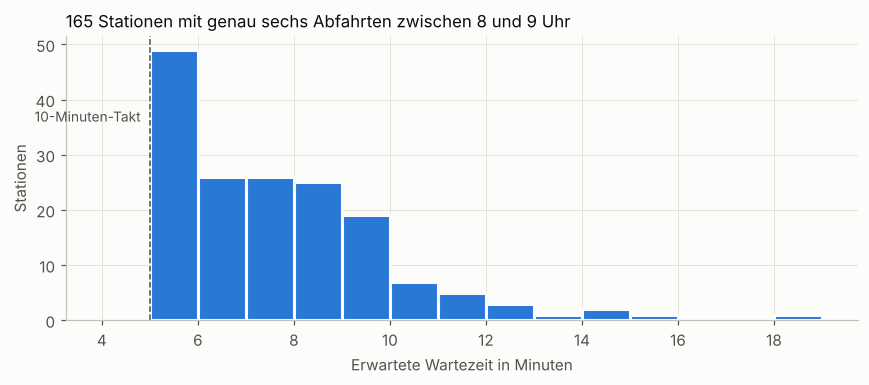

In [4]:
werktag = takt[STICHTAGE[0]]
sechs = werktag[(werktag["stunde"] == 8) & (werktag["abfahrten"] == 6)]
namen = stand["stops"].set_index("stop_id")["stop_name"]

fig, ax = plt.subplots(figsize=(8, 3.6))
ax.hist(sechs["erwartete_wartezeit_min"], bins=range(4, 20), color=FARBE["Werktag"], edgecolor="#fcfcfb", linewidth=2)
ax.axvline(5, color=TEXT2, linewidth=1, linestyle="--")
ax.annotate("10-Minuten-Takt", (5, ax.get_ylim()[1] * 0.7), xytext=(-6, 0), textcoords="offset points",
            ha="right", color=TEXT2, fontsize=9)
ax.set_xlabel("Erwartete Wartezeit in Minuten")
ax.set_ylabel("Stationen")
ax.set_title(f"{len(sechs)} Stationen mit genau sechs Abfahrten zwischen 8 und 9 Uhr", loc="left", color=TEXT, fontsize=11)
fig.tight_layout()
fig.savefig(GRAFIKEN / "sechs_abfahrten.png")

beispiele = pd.concat([sechs.nsmallest(3, "erwartete_wartezeit_min"), sechs.nlargest(3, "erwartete_wartezeit_min")])
beispiele.assign(name=namen.reindex(beispiele["station_id"]).values)[
    ["name", "abfahrten", "groesster_abstand_min", "erwartete_wartezeit_min"]].round(1)

## Gemeinden

Jede Station bekommt über ihre Koordinaten eine Gemeinde (Punkt in Polygon). Ausgewertet werden die 57 Gemeinden der vier Kreise, die ganz zum KVV gehören (E11). Stationen ohne Gemeinde werden gezählt und angezeigt, nicht verworfen.

In [5]:
gemeinden = lies_gemeinden(GEODATEN)
zugeordnet, ohne_gemeinde = ordne_zu(stationen_mit_koordinaten(stand["stops"]), gemeinden)
kern = zugeordnet[zugeordnet["kreis"].isin(KERNGEBIET)]
print(f"Stationen: {len(zugeordnet) + len(ohne_gemeinde)}, zugeordnet: {len(zugeordnet)}, ohne Gemeinde: {len(ohne_gemeinde)}")
print(f"Kerngebiet: {len(kern)} Stationen in {kern['ags'].nunique()} Gemeinden")
ohne_gemeinde[["station_id", "stop_name", "stop_lat", "stop_lon"]]

Stationen: 2078, zugeordnet: 2065, ohne Gemeinde: 13
Kerngebiet: 1768 Stationen in 57 Gemeinden


,station_id,stop_name,stop_lat,stop_lon
0,Pfr:24067:10331,Roeschwoog Sud,48.823944,8.032008
1,Pfr:24067:1342,Soufflenheim Centre de secours,48.832466,7.961149
2,Pfr:24067:1811,Beinheim Route du Rhin,48.858643,8.084847
3,fr:24067:1899:0:1,Roppenheim Village de Marques,48.838420,8.084936
4,Pfr:24067:3166,Seltz Le Seltzbach,48.894688,8.104340
5,Pfr:24067:326,Kesseldorf Centre,48.875815,8.068955
6,Pfr:24067:327,Beinheim Mairie,48.863046,8.084281
7,Pfr:24067:328,Roppenheim Centre,48.843375,8.055265
8,Pfr:24067:334,Roeschwoog Gare,48.834216,8.030732
9,Pfr:24067:335,Roeschwoog Centre,48.827155,8.035367


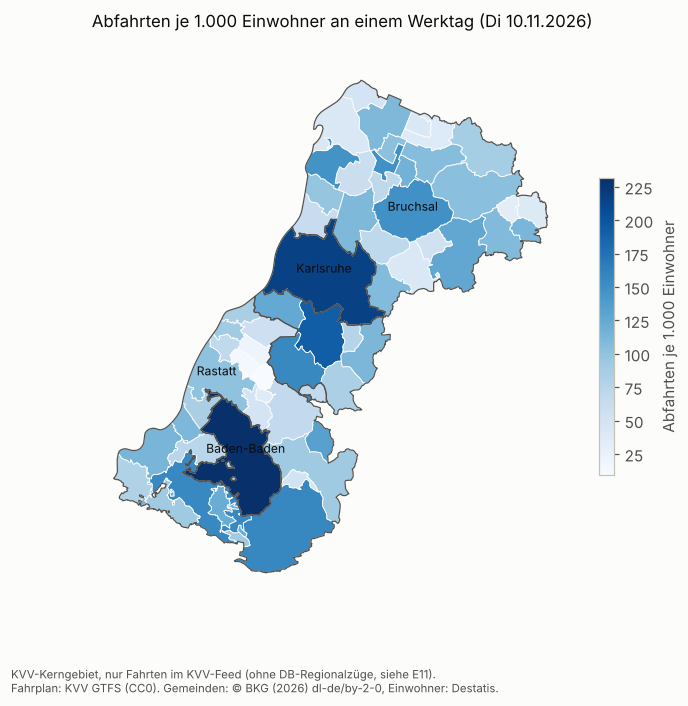

In [6]:
werktag_gem = je_gemeinde(abfahrten_im_abendfenster(stand, STICHTAGE[0]), kern, STICHTAGE[0])
sonntag_gem = je_gemeinde(abfahrten_im_abendfenster(stand, STICHTAGE[2]), kern, STICHTAGE[2])

flaechen = gemeinden.merge(werktag_gem[["ags", "je_1000_einwohner"]], on="ags")
kreise = flaechen.dissolve(by="kreis")

fig, ax = plt.subplots(figsize=(7, 7))
flaechen.plot(column="je_1000_einwohner", cmap="Blues", ax=ax, edgecolor="#fcfcfb", linewidth=0.6,
              legend=True, legend_kwds={"label": "Abfahrten je 1.000 Einwohner", "shrink": 0.5})
kreise.boundary.plot(ax=ax, color=TEXT2, linewidth=0.8)
for _, z in flaechen.nlargest(4, "einwohner").iterrows():
    p = z.geometry.representative_point()
    ax.annotate(z["gemeinde"], (p.x, p.y), ha="center", fontsize=8, color=TEXT)
ax.set_axis_off()
ax.set_title("Abfahrten je 1.000 Einwohner an einem Werktag (Di 10.11.2026)", loc="left", color=TEXT, fontsize=11)
fig.text(0.02, 0.02, "KVV-Kerngebiet, nur Fahrten im KVV-Feed (ohne DB-Regionalzüge, siehe E11).\n"
         "Fahrplan: KVV GTFS (CC0). Gemeinden: © BKG (2026) dl-de/by-2-0, Einwohner: Destatis.",
         color=TEXT2, fontsize=7.5)
fig.savefig(GRAFIKEN / "abfahrten_je_einwohner.png", bbox_inches="tight")

In [7]:
spalten = ["gemeinde", "einwohner", "abfahrten", "je_1000_einwohner"]
pd.concat({
    "wenigste": werktag_gem.nsmallest(8, "je_1000_einwohner")[spalten],
    "meiste": werktag_gem.nlargest(5, "je_1000_einwohner")[spalten],
}).round(1)

gemeinde  einwohner  abfahrten  je_1000_einwohner
wenigste 49    Muggensturm     6103.0         58                9.5
         50       Ötigheim     5004.0         75               15.0
         35     Bietigheim     6473.0        138               21.3
         19   Zaisenhausen     1885.0         63               33.4
         36     Bischweier     3046.0        109               35.8
         23  Bad Schönborn    13529.0        521               38.5
         15       Sulzfeld     5112.0        202               39.5
         14   Philippsburg    13765.0        573               41.6
meiste   0     Baden-Baden    56952.0      13184              231.5
         1       Karlsruhe   309247.0      66882              216.3
         4       Ettlingen    38557.0       7418              192.4
         41        Forbach     4571.0        721              157.7
         37           Bühl    28433.0       4453              156.6

## Abends und sonntags

Letzte Abfahrt im Fenster von 4 bis 4 Uhr (E11), also inklusive Nachtverkehr nach Mitternacht. "Ohne Abfahrt nach 20 Uhr" heißt: zwischen 20 Uhr und 4 Uhr fährt in der ganzen Gemeinde nichts ab, jedenfalls nichts, was im KVV-Feed steht.

In [8]:
def uhrzeit(ts, tag):
    if pd.isna(ts):
        return "keine Abfahrt"
    tage = (ts.normalize() - pd.Timestamp(tag)).days
    return ts.strftime("%H:%M") + (" (+1 Tag)" if tage else "")

abend = werktag_gem[["ags", "gemeinde", "einwohner"]].copy()
abend["letzte Abfahrt Werktag"] = [uhrzeit(t, STICHTAGE[0]) for t in werktag_gem["letzte_abfahrt"]]
abend["nach 20 Uhr Werktag"] = werktag_gem["abfahrten_nach_20"].values
s = sonntag_gem.set_index("ags")
abend["letzte Abfahrt Sonntag"] = [uhrzeit(s.loc[a, "letzte_abfahrt"], STICHTAGE[2]) for a in abend["ags"]]
abend["nach 20 Uhr Sonntag"] = s.loc[abend["ags"], "abfahrten_nach_20"].values
abend[(abend["nach 20 Uhr Werktag"] == 0) | (abend["nach 20 Uhr Sonntag"] == 0)].drop(columns="ags").sort_values("einwohner", ascending=False)

,gemeinde,einwohner,letzte Abfahrt Werktag,nach 20 Uhr Werktag,letzte Abfahrt Sonntag,nach 20 Uhr Sonntag
14,Philippsburg,13765.0,20:21,6,keine Abfahrt,0
23,Bad Schönborn,13529.0,21:05,14,19:15,0
22,Graben-Neudorf,12496.0,19:40,0,keine Abfahrt,0
29,Oberhausen-Rheinhausen,9515.0,20:46,12,keine Abfahrt,0
33,Dettenheim,6753.0,23:54,61,keine Abfahrt,0
8,Kronau,6077.0,20:36,6,keine Abfahrt,0
34,Au am Rhein,3389.0,20:47,8,keine Abfahrt,0
54,Steinmauern,3198.0,20:59,3,keine Abfahrt,0


## Einschränkungen

- **Nur der KVV-Feed.** Regionalzüge und S-Bahnen der DB (zum Beispiel die S-Bahn Rhein-Neckar über Graben-Neudorf) stehen nicht im KVV-GTFS. Dazu kommen Baustellen: Muggensturm hat am Stichtag fast nur Schienenersatzverkehr. Gemeinden, die vor allem über solche Züge angebunden sind, erscheinen hier schlechter versorgt, als sie sind. Graben-Neudorf ohne Abfahrt nach 20 Uhr ist deshalb ein Befund über den Datensatz, nicht über den Ort. Siehe E11 und den Abgleich in `docs/befunde.md`.
- **Alle Richtungen zusammen.** Die Wartezeit gilt für "irgendeine Abfahrt", nicht für eine bestimmte Richtung (E10).
- **Ein Stand, drei Tage.** Ebene 2 (wie sich der Fahrplan von Stand zu Stand ändert) kommt mit Phase 4.